# Tarea 1 EDA pasajeros del Titanic - Daniel Nieto Bouza

En esta tarea se va a realizar un EDA de los datos del dataset del Titanic.

El objetivo es conocer las carecteristicas de los pasajeros en investigar que variables estan asociadas a la supervivencia.

### Impotamos las liberiras necesarias y cargampos el dataset en una variable
Despues de cargar los datos mostrare las primeras filas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("./dataset/Titanic.csv")
df.head(5)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 3.2. Dimensiones, estructura y tipos de variables
Mostramos el numero de filas, columnas y la informacion general del dataset

In [3]:
print(f"Número de filas: {df.shape[0]}")
print(f"Número de columnas: {df.shape[1]}")
print("\nInformación de las columnas:")
df.info()

Número de filas: 891
Número de columnas: 12

Información de las columnas:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


### 3.3. Diccionario de variables

Las columnas más relevantes para este análisis son:

- Survived: resultado de supervivencia, donde 0 significa que no sobrevivió y 1 que sobrevivió.
- Pclass: clase del billete, codificada como 1, 2 o 3.
- Sex: sexo registrado en el dataset.
- Age: edad del pasajero.
- SibSp: número de hermanos, hermanas o cónyuge a bordo.
- Parch: número de padres o hijos a bordo.
- Fare: tarifa pagada.
- Embarked: puerto de embarque.
- Name, Ticket y Cabin: nombre, número de billete y cabina. 


## 4. Revisión de tipos de datos

Cambiamos el tipo de variable de Survives, Pclass, Sex y Embarked a category para que los tipos sean mas coherentes

In [5]:
print("Tipos originales:")
display(df.dtypes)

# Convertimos variables de grupo a categorías cuando están presentes.
for col in ["Survived", "Pclass", "Sex", "Embarked"]:
    if col in df.columns:
        df[col] = df[col].astype("category")

print("Tipos después de ajustar las variables categóricas:")
display(df.dtypes)

Tipos originales:


PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Tipos después de ajustar las variables categóricas:


PassengerId       int64
Survived       category
Pclass         category
Name                str
Sex            category
Age             float64
SibSp             int64
Parch             int64
Ticket              str
Fare            float64
Cabin               str
Embarked       category
dtype: object

## 5. Gestionamos los valores nulos

En este caso vemos que las columans con valores nulos son Cabin, Age y Embarked

In [4]:
ausentes = pd.DataFrame({
    "Valores ausentes": df.isna().sum(),
    "Porcentaje (%)": (df.isna().mean() * 100).round(2)
}).sort_values("Porcentaje (%)", ascending=False)

print(ausentes)

             Valores ausentes  Porcentaje (%)
Cabin                     687           77.10
Age                       177           19.87
Embarked                    2            0.22
PassengerId                 0            0.00
Name                        0            0.00
Pclass                      0            0.00
Survived                    0            0.00
Sex                         0            0.00
Parch                       0            0.00
SibSp                       0            0.00
Fare                        0            0.00
Ticket                      0            0.00


### 5.1. Decisión sobre los valores ausentes

En este caso dejaremos los valores ausentes en el dataset, lo unuco que la columna Cabin no la utilizaremos para los analisis porque tiene demasiados valores nulos


## 6. Gestion de valores duplicados

Vamos a comprobar si existen filas duplicadas en el dataset

In [ ]:
print("Filas duplicadas:", df.duplicated().sum())


Filas duplicadas: 0


## 7. Distribución de las variables

### 7.1. Variables numéricas: histogramas

Los histogramas muestran cómo se distribuyen las variables numéricas. Se estudiarán Age, Fare, SibSp y Parch


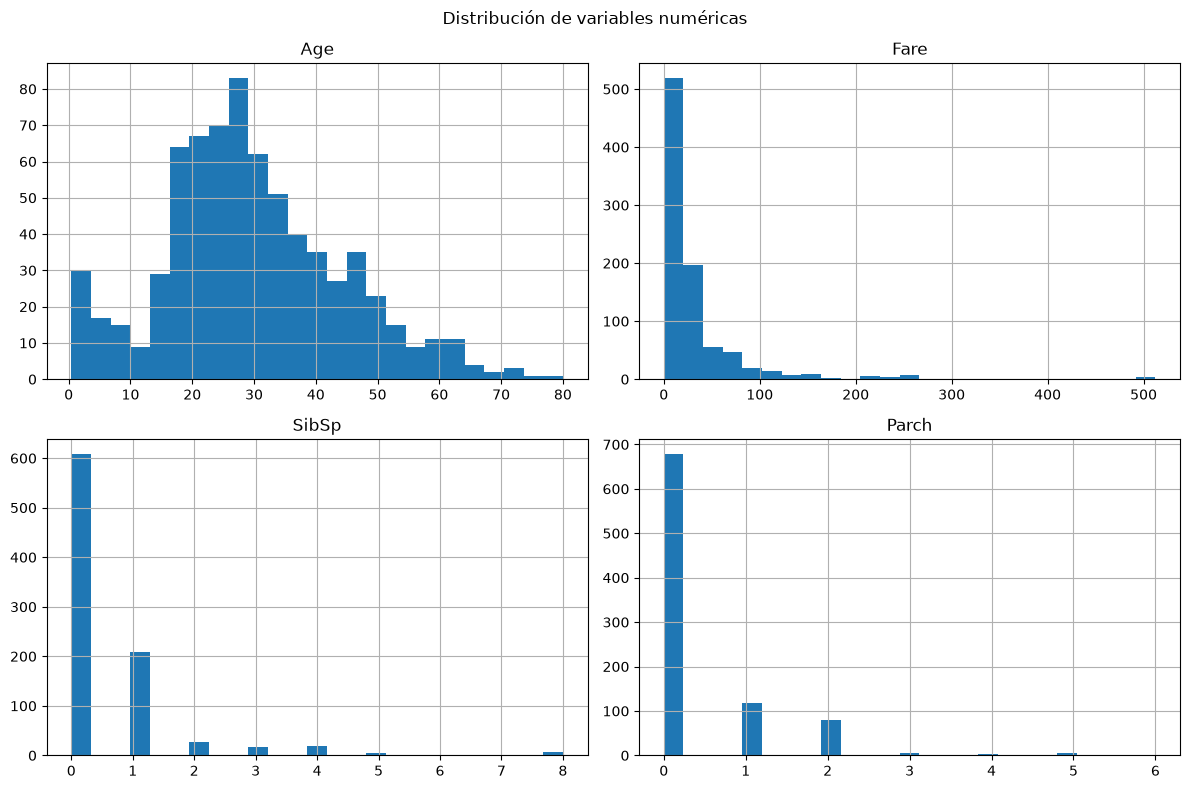

In [16]:
columnas_numericas = [c for c in ["Age", "Fare", "SibSp", "Parch"] if c in df.columns]

df[columnas_numericas].hist(
    bins=25,
    figsize=(12, 8),
)
plt.suptitle("Distribución de variables numéricas")
plt.tight_layout()
plt.show()

### 7.2. Resumen estadístico


In [17]:
df[["Age", "Fare", "SibSp", "Parch"]].describe()

,Age,Fare,SibSp,Parch
count,714.000000,891.000000,891.000000,891.000000
mean,29.699118,32.204208,0.523008,0.381594
std,14.526497,49.693429,1.102743,0.806057
min,0.420000,0.000000,0.000000,0.000000
25%,20.125000,7.910400,0.000000,0.000000
50%,28.000000,14.454200,0.000000,0.000000
75%,38.000000,31.000000,1.000000,0.000000
max,80.000000,512.329200,8.000000,6.000000


### 7.3. Porcentajes en las siguientes variables

Hacemos los porcentajes de las variables Survived, Pclass, Sex y Embarked.

In [ ]:

for col in ["Survived", "Pclass", "Sex", "Embarked"]:
    if col in df.columns:
        print(f"\nFrecuencias de {col}:")

        frecuencias = df[col].value_counts(dropna=False)
        porcentajes = df[col].value_counts(dropna=False, normalize=True) * 100

        tabla = pd.DataFrame({
            "Frecuencia": frecuencias,
            "Porcentaje (%)": porcentajes.round(2)
        })

        display(tabla)


Frecuencias de Survived:


,Frecuencia,Porcentaje (%)
Survived,,
0,549,61.62
1,342,38.38



Frecuencias de Pclass:


,Frecuencia,Porcentaje (%)
Pclass,,
3,491,55.11
1,216,24.24
2,184,20.65



Frecuencias de Sex:


,Frecuencia,Porcentaje (%)
Sex,,
male,577,64.76
female,314,35.24



Frecuencias de Embarked:


,Frecuencia,Porcentaje (%)
Embarked,,
S,644,72.28
C,168,18.86
Q,77,8.64
NaN,2,0.22


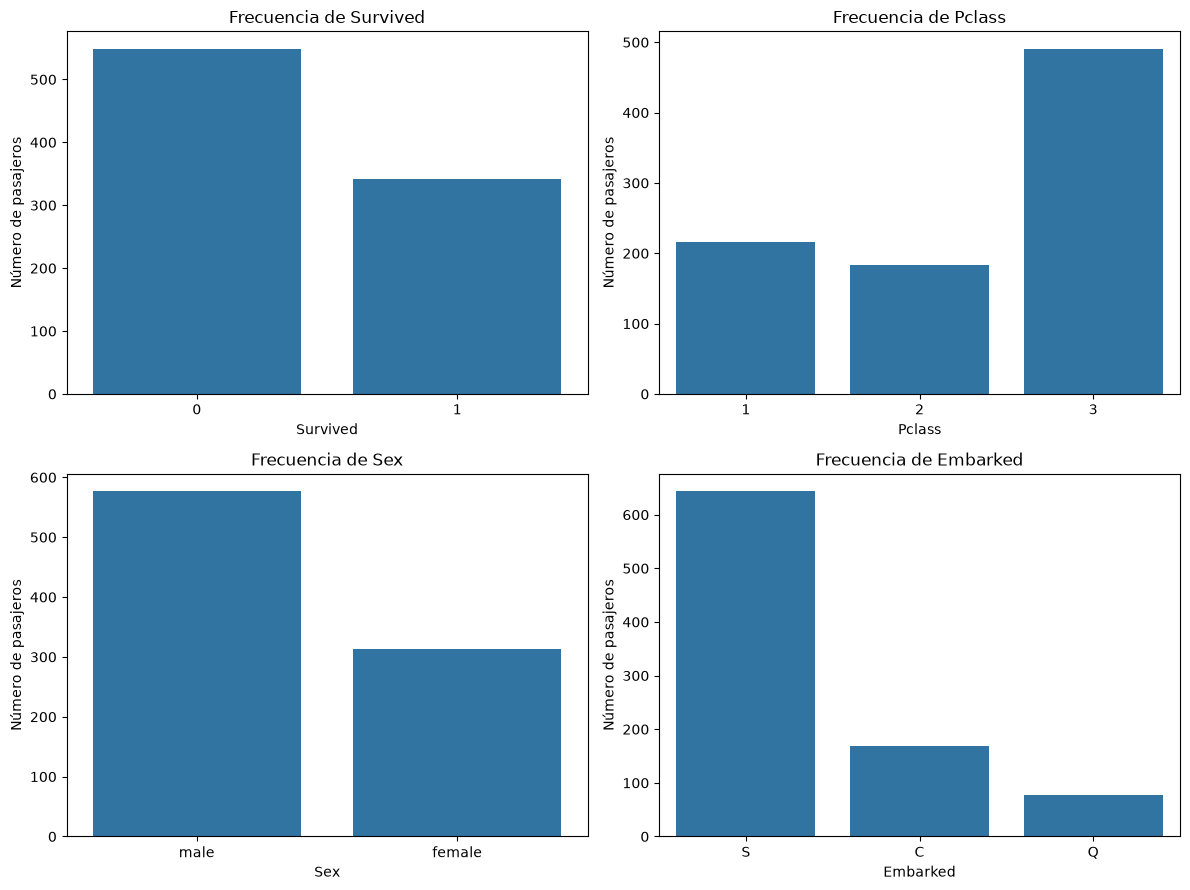

In [ ]:

columnas = ["Survived", "Pclass", "Sex", "Embarked"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for ax, col in zip(axes, columnas):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"Frecuencia de {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Número de pasajeros")

plt.tight_layout()
plt.show()

## 8. Análisis de la supervivencia

La variable Survived es la mas importante del dataset. Se pone como 0 para no superviviente y 1 para superviviente. .


In [ ]:
conteo_supervivencia = df["Survived"].value_counts().sort_index()
porcentaje_supervivencia = df["Survived"].value_counts(normalize=True).sort_index() * 100

resumen_supervivencia = pd.DataFrame({
    "Número de pasajeros": conteo_supervivencia,
    "Porcentaje (%)": porcentaje_supervivencia.round(2)
})
display(resumen_supervivencia)

,Número de pasajeros,Porcentaje (%)
Survived,,
0,549,61.62
1,342,38.38


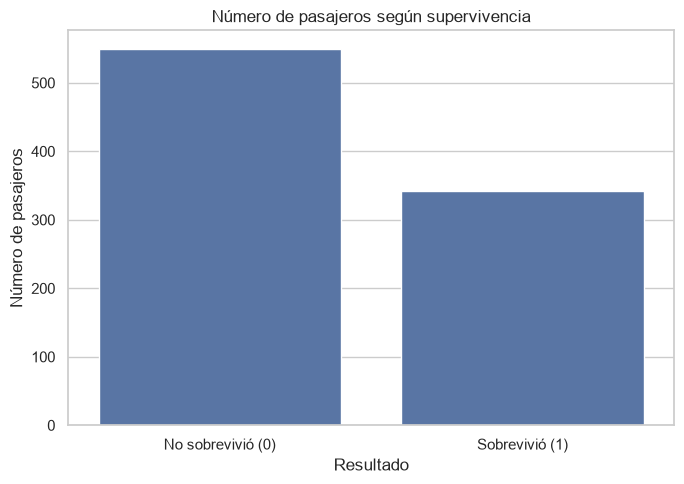

In [14]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Survived")
plt.xticks([0, 1], ["No sobrevivió (0)", "Sobrevivió (1)"])
plt.title("Número de pasajeros según supervivencia")
plt.xlabel("Resultado")
plt.ylabel("Número de pasajeros")
plt.tight_layout()
plt.show()

## 9. Análisis de supervivencia con el sexo de la persona

Se compara la tasa de supervivencia por sexo. Para cada grupo, la media de Survived es la proporción que sobrevivio.

In [29]:

tasa_sexo = df.groupby("Sex")["Survived"].mean() * 100

tasa_sexo = tasa_sexo.sort_values(ascending=False).round(2)

tasa_sexo = tasa_sexo.rename("Supervivencia (%)")

display(tasa_sexo.to_frame())

,Supervivencia (%)
Sex,
female,74.20
male,18.89


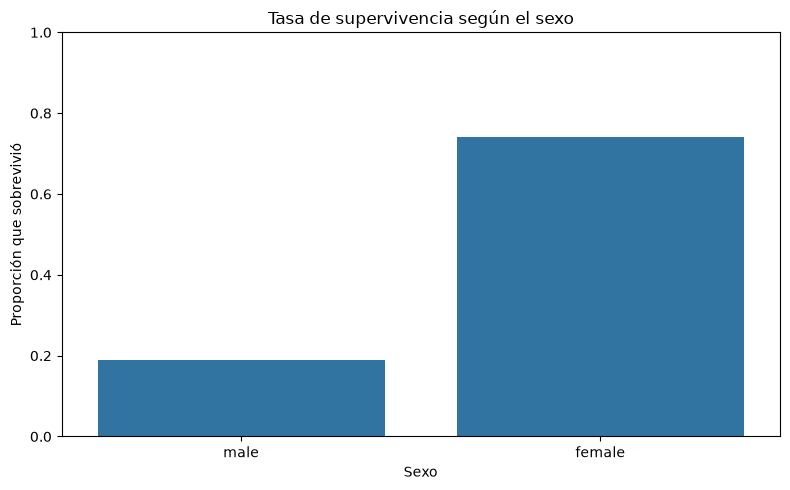

In [28]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Sex", y="Survived", errorbar=None)
plt.title("Tasa de supervivencia según el sexo")
plt.xlabel("Sexo")
plt.ylabel("Proporción que sobrevivió")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 10. Análisis de supervivencia con la clase de billete que tenia la persona

Pclass identifica la clase del billete. Se tratará como categoría porque interesa comparar los grupos 1, 2 y 3.

Voy a la tasa de supervivencia de cada clase y representarlo por un gráfico de barras.

In [31]:
tasa_clase = df.groupby("Pclass")["Survived"].mean() * 100

tasa_clase = tasa_clase.round(2)

tasa_clase = tasa_clase.rename("Supervivencia (%)")

display(tasa_clase.to_frame())

,Supervivencia (%)
Pclass,
1,62.96
2,47.28
3,24.24


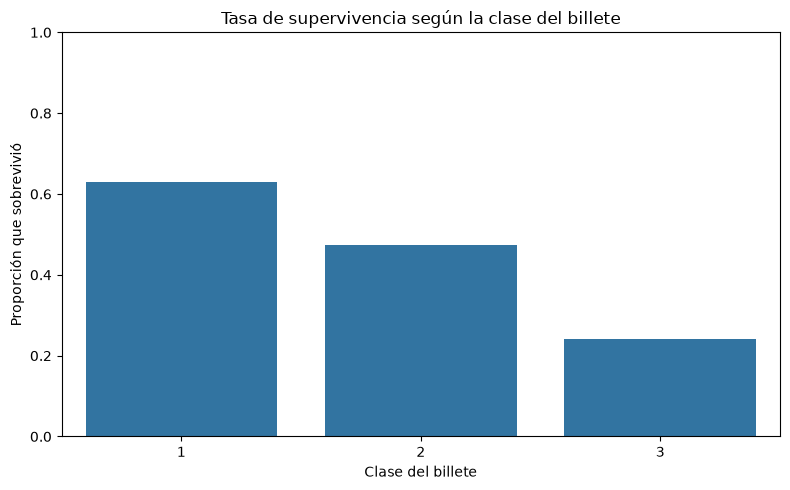

In [32]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Pclass", y="Survived", order=sorted(df["Pclass"].dropna().unique()), errorbar=None)
plt.title("Tasa de supervivencia según la clase del billete")
plt.xlabel("Clase del billete")
plt.ylabel("Proporción que sobrevivió")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Se ve que la clase con mas supervivientes es la 1 y va descediendo hasta la 3

## 11. Edad y supervivencia

Se comparan las edades disponibles de quienes sobrevivieron y quienes no. Los resultados son solo a pasajeros con edad registrada.

In [33]:
display(df.groupby("Survived")["Age"].describe())

,count,mean,std,min,25%,50%,75%,max
Survived,,,,,,,,
0,424.0,30.626179,14.172110,1.00,21.0,28.0,39.0,74.0
1,290.0,28.343690,14.950952,0.42,19.0,28.0,36.0,80.0


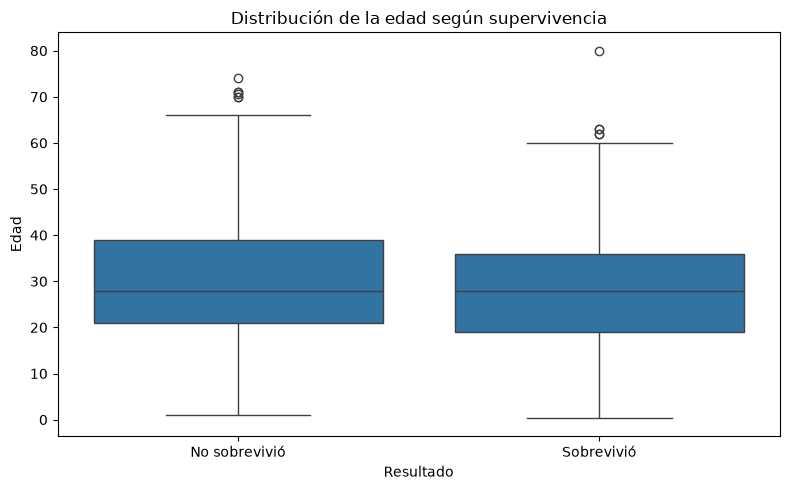

In [34]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Survived", y="Age")
plt.xticks([0, 1], ["No sobrevivió", "Sobrevivió"])
plt.title("Distribución de la edad según supervivencia")
plt.xlabel("Resultado")
plt.ylabel("Edad")
plt.tight_layout()
plt.show()

## 11. Matriz de correlacion en variables numericas

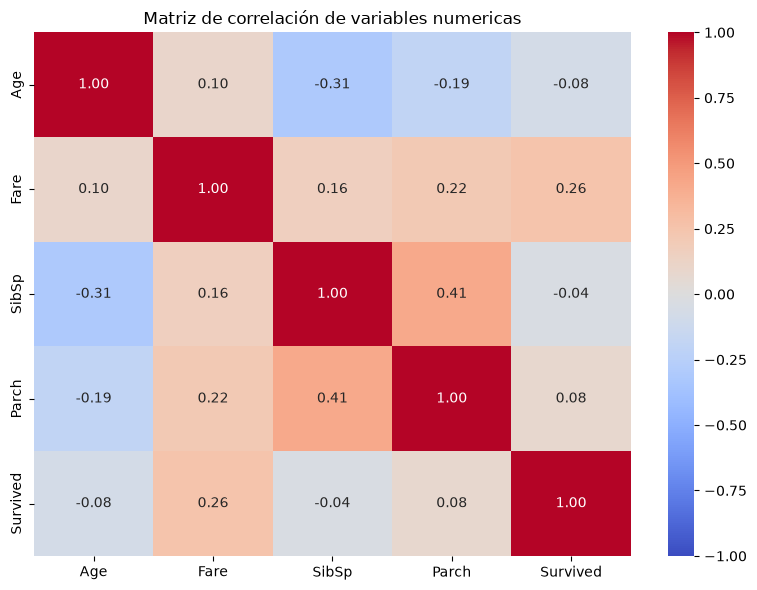

In [43]:
columnas_corr = [c for c in ["Age", "Fare", "SibSp", "Parch", "Survived"] if c in df.columns]
corr = df[columnas_corr].astype(float).corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1, fmt=".2f")
plt.title("Matriz de correlación de variables numericas")
plt.tight_layout()
plt.show()


## 15. Resumen de resultados principales

La siguiente celda calcula algunos indicadores clave para que las conclusiones se basen en los resultados reales del dataset cargado.

In [45]:

print("Pasajeros registrados:", len(df))

supervivencia = df["Survived"].mean() * 100
print(f"Supervivencia global: {supervivencia:.2f}%")

print(f"Edad mediana: {df['Age'].median():.2f}")
print(f"Tarifa mediana: {df['Fare'].median():.2f}")

print("\nSupervivencia por sexo (%):")
print((df.groupby("Sex")["Survived"].mean() * 100).round(2))

print("\nSupervivencia por clase (%):")
print((df.groupby("Pclass")["Survived"].mean() * 100).round(2))

Pasajeros registrados: 891
Supervivencia global: 38.38%
Edad mediana: 28.00
Tarifa mediana: 14.45

Supervivencia por sexo (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

Supervivencia por clase (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


## 16. Conclusiones

Al finalizar la ejecución del notebook, completa las siguientes conclusiones con los valores obtenidos. Es importante no dejar afirmaciones genéricas sin relacionarlas con las tablas y gráficos.

1. **Composición de la muestra:** indica cuántos registros y variables contiene el dataset y qué características predominan.
2. **Calidad de los datos:** identifica las columnas con más ausencias y explica por qué no se eliminaron indiscriminadamente todas las filas incompletas.
3. **Supervivencia global:** cita el porcentaje calculado y señala si predominan los supervivientes o los no supervivientes.
4. **Sexo y supervivencia:** compara las tasas y describe la diferencia observada.
5. **Clase y supervivencia:** identifica las clases con tasas mayores y menores.
6. **Edad y tarifas:** comenta las distribuciones, la asimetría y los posibles valores atípicos que aparecen en los gráficos.
7. **Limitaciones:** recuerda que los resultados describen asociaciones, que hay variables incompletas y que el análisis exploratorio no demuestra causalidad.

### Conclusión final

El EDA permite conocer la estructura del dataset, evaluar la calidad de los datos y descubrir diferencias entre grupos de pasajeros. Las conclusiones definitivas deben apoyarse en los porcentajes, estadísticas y gráficos obtenidos al ejecutar las celdas. No se eliminan automáticamente los valores extremos porque pueden representar situaciones reales, y los valores ausentes se gestionan de forma selectiva según el análisis. Como trabajo futuro, podría estudiarse conjuntamente el sexo, la clase y la edad para comprobar si las diferencias observadas se mantienen al considerar varias variables a la vez.